In [1]:
!pip uninstall -y torch torchvision torchaudio
!pip install -U --no-cache-dir torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126

Found existing installation: torch 2.10.0+cu128
Uninstalling torch-2.10.0+cu128:
  Successfully uninstalled torch-2.10.0+cu128
Found existing installation: torchvision 0.25.0+cu128
Uninstalling torchvision-0.25.0+cu128:
  Successfully uninstalled torchvision-0.25.0+cu128
Found existing installation: torchaudio 2.10.0+cu128
Uninstalling torchaudio-2.10.0+cu128:
  Successfully uninstalled torchaudio-2.10.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.8/296.8 MB 164.4 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 184.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 284.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 172.2 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 304.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 228.3 MB/s eta 0:00:00a 0:00:01
    

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.4 MB/s eta 0:00:00a 0:00:01


In [2]:
import os
import shutil
import random
from pathlib import Path
from sklearn.model_selection import train_test_split

# =========================================================
# PATHS
# =========================================================
SOURCE_ROOT = Path("/kaggle/input/datasets/ahmedshayan1/brain-mri-tummor")
SOURCE_IMAGES = SOURCE_ROOT / "train" / "images"
SOURCE_LABELS = SOURCE_ROOT / "train" / "labels"

NEW_ROOT = Path("/kaggle/working/brain_mri_yolo_dataset")

TRAIN_IMAGES = NEW_ROOT / "train" / "images"
TRAIN_LABELS = NEW_ROOT / "train" / "labels"
VAL_IMAGES   = NEW_ROOT / "valid" / "images"
VAL_LABELS   = NEW_ROOT / "valid" / "labels"

# =========================================================
# SETTINGS
# =========================================================
VAL_SPLIT = 0.2
SEED = 42
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(SEED)

# =========================================================
# CREATE FOLDERS
# =========================================================
for p in [TRAIN_IMAGES, TRAIN_LABELS, VAL_IMAGES, VAL_LABELS]:
    p.mkdir(parents=True, exist_ok=True)

print("Source images exists:", SOURCE_IMAGES.exists(), SOURCE_IMAGES)
print("Source labels exists:", SOURCE_LABELS.exists(), SOURCE_LABELS)

# =========================================================
# COLLECT IMAGE-LABEL PAIRS
# =========================================================
all_images = []
for f in SOURCE_IMAGES.iterdir():
    if f.is_file() and f.suffix.lower() in VALID_EXTS:
        label_file = SOURCE_LABELS / (f.stem + ".txt")
        if label_file.exists():
            all_images.append(f)
        else:
            print(f"Skipping image without label: {f.name}")

print(f"Total paired images found: {len(all_images)}")

if len(all_images) == 0:
    raise ValueError("No image-label pairs found. Please check dataset paths.")

# =========================================================
# SPLIT DATA
# =========================================================
train_files, val_files = train_test_split(
    all_images,
    test_size=VAL_SPLIT,
    random_state=SEED,
    shuffle=True
)

print(f"Train files: {len(train_files)}")
print(f"Valid files: {len(val_files)}")

# =========================================================
# COPY FILES
# =========================================================
def copy_files(file_list, dst_img_dir, dst_lbl_dir):
    for img_path in file_list:
        lbl_path = SOURCE_LABELS / (img_path.stem + ".txt")

        shutil.copy2(img_path, dst_img_dir / img_path.name)
        shutil.copy2(lbl_path, dst_lbl_dir / lbl_path.name)

copy_files(train_files, TRAIN_IMAGES, TRAIN_LABELS)
copy_files(val_files, VAL_IMAGES, VAL_LABELS)

print("Dataset split complete.")

# =========================================================
# CREATE NEW data.yaml
# =========================================================
yaml_content = f"""
path: {NEW_ROOT}
train: train/images
val: valid/images

nc: 1
names: ['tumor']
""".strip()

yaml_path = NEW_ROOT / "data.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("\nCreated YAML file:")
print(yaml_path)
print("\nYAML content:\n")
print(yaml_content)

Source images exists: True /kaggle/input/datasets/ahmedshayan1/brain-mri-tummor/train/images
Source labels exists: True /kaggle/input/datasets/ahmedshayan1/brain-mri-tummor/train/labels
Total paired images found: 3311
Train files: 2648
Valid files: 663
Dataset split complete.

Created YAML file:
/kaggle/working/brain_mri_yolo_dataset/data.yaml

YAML content:

path: /kaggle/working/brain_mri_yolo_dataset
train: train/images
val: valid/images

nc: 1
names: ['tumor']


In [3]:
!yolo task=detect mode=train \
    model=yolo11s.pt \
    data=/kaggle/working/brain_mri_yolo_dataset/data.yaml \
    epochs=100 \
    imgsz=640 \
    batch=16 \
    device=0 \
    project=/kaggle/working/runs/detect \
    name=brain_mri_tumor_yolo

Ultralytics 8.4.37 🚀 Python-3.12.12 torch-2.11.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/brain_mri_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=brain_mri_tumor_yolo, nbs=64, nms=False, opset=None, optimize=False, opti

Results saved to /kaggle/working/brain_mri_single_prediction/pred
{
    "image_path": "/kaggle/input/datasets/ahmedshayan1/normalll-mri/Normal/images.jpg",
    "model_path": "/kaggle/input/models/ahmedshayan1/detection/gemmacpp/default/1/brain_mri_tumor_yolo/weights/best.pt",
    "num_detections": 1,
    "best_detection": {
        "class_id": 0,
        "class_name": "tumor",
        "confidence": 0.850263,
        "box_xyxy": [
            105.28202056884766,
            59.3099365234375,
            142.23709106445312,
            79.29070281982422
        ]
    },
    "detections": [
        {
            "class_id": 0,
            "class_name": "tumor",
            "confidence": 0.850263,
            "box_xyxy": [
                105.28202056884766,
                59.3099365234375,
                142.23709106445312,
                79.29070281982422
            ]
        }
    ],
    "annotated_image_path": "/kaggle/working/brain_mri_single_prediction/pred/images.jpg"
}


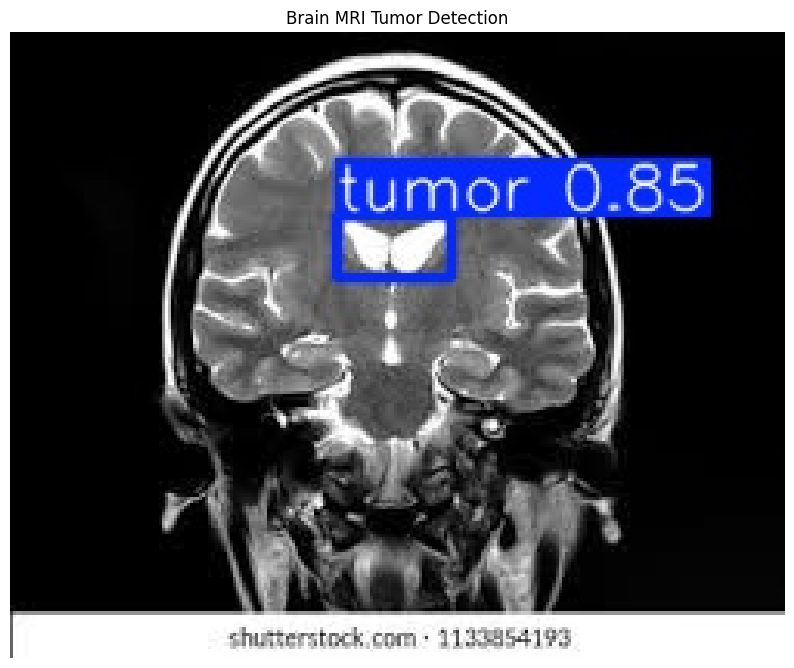

In [15]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import json

# ============================================
# PATHS
# ============================================
MODEL_PATH = "/kaggle/input/models/ahmedshayan1/detection/gemmacpp/default/1/brain_mri_tumor_yolo/weights/best.pt"
IMAGE_PATH = "/kaggle/input/datasets/ahmedshayan1/normalll-mri/Normal/images.jpg"

SAVE_DIR = Path("/kaggle/working/brain_mri_single_prediction")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================
# SETTINGS
# ============================================
CONF_THRES = 0.25
IOU_THRES = 0.50

# ============================================
# LOAD MODEL
# ============================================
model = YOLO(MODEL_PATH)

# ============================================
# RUN INFERENCE
# ============================================
results = model.predict(
    source=IMAGE_PATH,
    conf=CONF_THRES,
    iou=IOU_THRES,
    save=True,
    project=str(SAVE_DIR),
    name="pred",
    exist_ok=True,
    verbose=False
)

r = results[0]

# ============================================
# PARSE RESULTS
# ============================================
detections = []

if r.boxes is not None and len(r.boxes) > 0:
    confs = r.boxes.conf.cpu().numpy()
    classes = r.boxes.cls.cpu().numpy().astype(int)
    xyxy = r.boxes.xyxy.cpu().numpy()

    for i in range(len(r.boxes)):
        cls_id = int(classes[i])
        conf = float(confs[i])
        box = [float(x) for x in xyxy[i]]

        detections.append({
            "class_id": cls_id,
            "class_name": model.names[cls_id],
            "confidence": round(conf, 6),
            "box_xyxy": box
        })

    best_idx = confs.argmax()
    best_cls_id = int(classes[best_idx])
    best_conf = float(confs[best_idx])
    best_box = [float(x) for x in xyxy[best_idx]]

    best_detection = {
        "class_id": best_cls_id,
        "class_name": model.names[best_cls_id],
        "confidence": round(best_conf, 6),
        "box_xyxy": best_box
    }
else:
    best_detection = None

# ============================================
# OUTPUT JSON
# ============================================
annotated_image_path = SAVE_DIR / "pred" / Path(IMAGE_PATH).name

output = {
    "image_path": IMAGE_PATH,
    "model_path": MODEL_PATH,
    "num_detections": len(detections),
    "best_detection": best_detection,
    "detections": detections,
    "annotated_image_path": str(annotated_image_path) if annotated_image_path.exists() else None
}

print(json.dumps(output, indent=4))

# ============================================
# SHOW ANNOTATED IMAGE
# ============================================
if annotated_image_path.exists():
    img = Image.open(annotated_image_path)

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Brain MRI Tumor Detection")
    plt.show()
else:
    print("Annotated image not found:", annotated_image_path)

In [5]:
import shutil
from pathlib import Path

SOURCE_DIR = Path("/kaggle/working/runs/detect/brain_mri_tumor_yolo")
ZIP_BASE = Path("/kaggle/working/brain_mri_tumor_yolo")

if not SOURCE_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {SOURCE_DIR}")

zip_path = shutil.make_archive(
    base_name=str(ZIP_BASE),
    format="zip",
    root_dir=str(SOURCE_DIR.parent),
    base_dir=str(SOURCE_DIR.name)
)

print("ZIP created successfully:")
print(zip_path)

ZIP created successfully:
/kaggle/working/brain_mri_tumor_yolo.zip
